# 7. Geographic Analysis

This section examines the spatial structure of the brewery dataset.

The analysis is intentionally separated into two versions:

- **`analysis_all_records`**: keeps all records that survived the earlier cleaning step. This is useful when multiple brewery records at the same physical coordinates may represent meaningful separate records.
- **`analysis_unique_records`**: removes records that are identical with respect to the previously defined physical/location identity columns. This is useful for checking whether geographic conclusions are sensitive to duplicate location identities.

The five main questions addressed here are:

1. **Coordinate coverage** — How much of the dataset has usable geographic information?
2. **Geographic centers** — Where are breweries geographically concentrated at overall, country, state/province, and city levels?
3. **Distance from center** — How far are breweries from the geographic center of their relevant region?
4. **Spatial dispersion** — How concentrated or geographically spread out is each region?
5. **Geographic outliers** — Which records or regions are unusually far from their geographic center?

> **Important:** The dataset's API coordinate fields were previously found to require the project's established geographic interpretation. The code below therefore creates `latitude_geo` from the source `longitude` field and `longitude_geo` from the source `latitude` field, rather than silently changing the original columns.


### Read this first: a first pass on uncorrected coordinates

This notebook is our first pass and ran on the coordinates as stored. Later we compared every record with the center of the city it names and found 8 records with latitude and longitude swapped, one longitude with the wrong sign (Mescan Brewery, Mayo) and one misplaced record. They are now corrected through `data/coordinate_corrections.csv`, which is applied when data is loaded (the databases keep the original values). This notebook does not apply it, so some results below are distorted:

- the minimum latitude in the range check and the bounding box comes from a swapped record;
- the dispersion of Alabama and Connecticut, and of Aveiro in Portugal, is inflated, because one swapped record drags each state's mean center far away;
- the three records farthest from their state center are swapped records.

State labels are used as stored, not harmonized: Belgium's regions appear under labels in three languages, and `MIssouri` is a separate one-record state next to Missouri.

The Geographic Analysis page of the dashboard (`pages/4_Geographic_Analysis.py`) recomputes all of this with the corrections and harmonized labels. It also adds a second origin: the state capital, or at city level the real city center from GeoNames (`data/reference_places.db`). The section texts of this notebook appear on that page word for word.

One correction to the intro above: the code does not exchange the two fields. `latitude_geo` is a copy of `latitude` and `longitude_geo` a copy of `longitude`. The stored orientation was already right for all but the swapped records.

In [1]:
# Purpose: Imports the libraries used for API requests, DataFrame manipulation, and numerical operations.

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


### Earlier loading steps (inactive)

The next cells are commented out. They record how we first fetched the snapshot from the Open Brewery DB API, wrote it to `data/raw_breweries.db`, and loaded the analysis files from older paths. They do nothing when run; the data is loaded from the two analysis databases further down.

In [2]:
# import sqlite3
# import pandas as pd
#
# conn = sqlite3.connect("analysis_all_records.db")
#
# analysis_all_records = pd.read_sql_query(
#     "SELECT * FROM analysis_all_records",
#     conn
# )
#
# conn.close()

In [3]:
# import sqlite3
# import pandas as pd
#
# conn1 = sqlite3.connect("analysis_unique_records.db")
#
# analysis_unique_records = pd.read_sql_query(
#     "SELECT * FROM analysis_unique_records",
#     conn1
# )
#
# conn1.close()

In [4]:
# analysis_unique_records.shape

In [5]:
# type(analysis_unique_records)

In [6]:
# analysis_unique_records.shape

In [7]:
# analysis_unique_records.isna().sum()

In [8]:
# analysis_unique_records.head()

In [9]:
# analysis_all_records.shape

In [10]:
# analysis_all_records.isna().sum()

In [11]:
# analysis_all_records.head()

In [12]:
# # Purpose: Fetches all brewery records from Open Brewery DB page by page (200 records per request) and stores the API results in a list.
#
# api_url = 'https://api.openbrewerydb.org/v1/breweries'
#
# brewery_records = []
#
# page_number = 1
#
# while True:
#
#     request_params = {
#         'per_page': 200,
#         'page': page_number
#     }
#
#     api_response = requests.get(api_url, params=request_params)
#     page_data = api_response.json()
#
#     if len(page_data) == 0:
#         break
#
#     brewery_records.extend(page_data)
#
#     page_number += 1


In [13]:
# # Purpose: Converts the list of brewery dictionaries returned by the API into a pandas DataFrame.
#
# raw_breweries_df = pd.DataFrame(brewery_records)

In [14]:
# # Purpose: Checks the number of rows and columns in the brewery DataFrame.
#
# raw_breweries_df.shape

In [15]:
# Purpose: Imports Python's `inspect` module so function signatures can be inspected.

# Not used by any active cell below.
import inspect

In [16]:
# #   @: Creates a SQLite SQLAlchemy database_engine and writes the brewery DataFrame to the `breweries` table, replacing an existing table.
#
# from sqlalchemy import create_engine
#
# database_engine = create_engine('sqlite:///data/raw_breweries.db')
#
# raw_breweries_df.to_sql(
#     'raw_breweries',
#     con=database_engine,
#     if_exists='replace',
#     index=False
# )

In [17]:
# #   @: Checks the notebook's current working directory and lists the files and folders available there.
#
# from pathlib import Path
# import pandas as pd
# from sqlalchemy import create_engine, inspect
#
# # Check the current working directory
# base_dir = Path.cwd()
#
# print("Current working directory:", base_dir)
# print("Files and folders:")
# print(list(base_dir.iterdir()))

In [18]:
# #   @: Builds the expected SQLite database path and checks whether the database file exists.
#
# db_path = base_dir / "data" / "raw_breweries.db"
#
# print("Database exists:", db_path.exists())
# print("Database path:", db_path)

In [19]:
# print("db_path:", db_path)
# print("absolute path:", db_path.resolve())
# print("exists:", db_path.exists())
# print("parent exists:", db_path.parent.exists())

In [20]:
# #   @: Inspects the SQLite database and lists its tables.
#
# database_engine = create_engine(
#     f"sqlite:///{db_path.as_posix()}"
# )
#
# # List all tables in the database
# db_inspector = inspect(database_engine)
#
# print("Tables:", db_inspector.get_table_names())

### Load the analysis datasets

Both files hold geocoded records only: 9,488 in `analysis_all_records` and 9,487 in `analysis_unique_records`. The record missing from the unique file is a Paulaner record in München that differs from another one only by its website (checked in the last cells of this notebook).

In [21]:
# Purpose: Contains notes/comments describing the section or intended code.

import pandas as pd
from sqlalchemy import create_engine

# Geocoded records only; exact duplicates were removed when this file was built.
engine = create_engine("sqlite:///data/analysis_all_records.db")

analysis_all_records = pd.read_sql(
    "SELECT * FROM analysis_all_records",
    con=engine
)

analysis_all_records.info()

<class 'pandas.DataFrame'>
RangeIndex: 9488 entries, 0 to 9487
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              9488 non-null   str    
 1   name            9488 non-null   str    
 2   brewery_type    9488 non-null   str    
 3   address_1       9340 non-null   str    
 4   address_2       322 non-null    str    
 5   address_3       38 non-null     str    
 6   city            9488 non-null   str    
 7   state_province  9488 non-null   str    
 8   postal_code     9487 non-null   str    
 9   country         9488 non-null   str    
 10  longitude       9488 non-null   float64
 11  latitude        9488 non-null   float64
 12  phone           8565 non-null   str    
 13  website_url     8631 non-null   str    
 14  state           9488 non-null   str    
 15  street          9340 non-null   str    
dtypes: float64(2), str(14)
memory usage: 2.8 MB


In [22]:
# Purpose: Contains notes/comments describing the section or intended code.

import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/analysis_unique_records.db")

analysis_unique_records = pd.read_sql(
    "SELECT * FROM analysis_unique_records",
    con=engine
)

analysis_unique_records.info()

<class 'pandas.DataFrame'>
RangeIndex: 9487 entries, 0 to 9486
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              9487 non-null   str    
 1   name            9487 non-null   str    
 2   brewery_type    9487 non-null   str    
 3   address_1       9339 non-null   str    
 4   address_2       322 non-null    str    
 5   address_3       38 non-null     str    
 6   city            9487 non-null   str    
 7   state_province  9487 non-null   str    
 8   postal_code     9486 non-null   str    
 9   country         9487 non-null   str    
 10  longitude       9487 non-null   float64
 11  latitude        9487 non-null   float64
 12  phone           8564 non-null   str    
 13  website_url     8630 non-null   str    
 14  state           9487 non-null   str    
 15  street          9339 non-null   str    
dtypes: float64(2), str(14)
memory usage: 2.8 MB


In [23]:
analysis_all_records.shape

(9488, 16)

In [24]:
analysis_all_records

,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
0,ae7b3174-8be8-4d53-a3a5-9b8240970eea,'s,brewpub,Friesener Straße 1,NaN,NaN,Kronach,Bayern,96317,Germany,11.327765,50.241246,+49 9261 628000,http://www.antla.de,Bayern,Friesener Straße 1
1,aa7cbe9b-3a0f-4888-9884-6186b0042b55,’t Drankorgel,micro,31a Geelsebaan,NaN,NaN,Mol,Vlaanderen,2400,Belgium,5.056955,51.176258,+32 496 76 40 63,http://tdrankorgel.be/,Vlaanderen,31a Geelsebaan
2,1034754f-abf9-4b42-bd6d-37e110ba4b1a,'T Kroontje,micro,62 Hogebrug,NaN,NaN,Lebbeke,Vlaanderen,9280,Belgium,4.091393,51.007888,+32 495 43 33 25,http://www.tkroontje.be/,Vlaanderen,62 Hogebrug
3,5128df48-79fc-4f0f-8b52-d06be54d0cec,(405) Brewing Co,micro,1716 Topeka St,NaN,NaN,Norman,Oklahoma,73069-8224,United States,-97.468182,35.257389,4058160490,http://www.405brewing.com,Oklahoma,1716 Topeka St
4,34e8c68b-6146-453f-a4b9-1f6cd99a5ada,1 of Us Brewing Company,micro,8100 Washington Ave,NaN,NaN,Mount Pleasant,Wisconsin,53406-3920,United States,-87.883364,42.720108,2624847553,https://www.1ofusbrewing.com,Wisconsin,8100 Washington Ave
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9483,57a70f5c-a995-4be1-949c-99244450940f,플레이그라운드 브루어리(playground Brewery),brewpub,"246-13, Isanpo-gil",Ilsanseo-gu,NaN,Goyang-si,Gyeonggido,10203,South Korea,126.702011,37.667795,031-912-2463,https://www.playgroundbrewery.com/,Gyeonggido,"246-13, Isanpo-gil"
9484,64a4f65c-47a9-4d8e-ad2e-3cc898b9689c,핸드앤몰트 (Hand and Malt),brewpub,"19, Hangang-daero 38ga-gil",NaN,NaN,Yongsan-gu,Seoul,04386,South Korea,126.970583,37.529857,070-7178-4011,http://handandmalt.com/,Seoul,"19, Hangang-daero 38ga-gil"
9485,a9541aa9-5c12-469b-8cbb-01fb5619cefc,허심청브루잉(Hursimchung Bru),brewpub,"23, Geumganggongwon-ro 20beon-gil",NaN,NaN,Dongnae-gu,Busan,47709,South Korea,129.082603,35.219902,051-550-2345,https://www.hotelnongshim.com/kr/index.php?pCode=hbrau_info,Busan,"23, Geumganggongwon-ro 20beon-gil"
9486,6f317bdc-458e-466f-bd2a-9ab398d46631,헤이스탁 브루어리(Haystack Brewery),brewpub,"25, Pangyogongwon-ro 3-gil",Bundang-gu,NaN,Seongnam-si,Gyeonggido,13477,South Korea,127.089061,37.391256,070-7631-1110,NaN,Gyeonggido,"25, Pangyogongwon-ro 3-gil"


In [25]:
# Create independent geographic-analysis copies.
# Keeping these copies separate prevents geographic calculations from changing
# the original analysis datasets used by the earlier EDA sections.

geographic_datasets = {
    "all_records": analysis_all_records.copy(),
    "unique_records": analysis_unique_records.copy()
}

# The project established that the source coordinate fields need to be interpreted
# with this orientation for geographic calculations.
for dataset_name, df in geographic_datasets.items():
    # No exchange happens here: latitude_geo is the stored latitude (see the note at the top).
    df["latitude_geo"] = df["latitude"]
    df["longitude_geo"] = df["longitude"]

    # Keep only records with both coordinates available for spatial calculations.
    # We do not drop them from the original analysis datasets; we create a
    # coordinate-complete geographic view instead.
    # Removes nothing here: both analysis files hold geocoded records only.
    geographic_datasets[dataset_name] = df.dropna(
        subset=["latitude_geo", "longitude_geo"]
    ).copy()

print("Geographic datasets created:")
for dataset_name, df in geographic_datasets.items():
    print(f"{dataset_name}: {df.shape[0]:,} coordinate-complete records")


Geographic datasets created:
all_records: 9,488 coordinate-complete records
unique_records: 9,487 coordinate-complete records


## 7.1 Coordinate Coverage

Before using coordinates for geographic analysis, we need to measure how complete the geographic information is.

Coverage is reported at two levels:

- **record coverage:** percentage of records with both latitude and longitude
- **coordinate coverage:** percentage of individual latitude/longitude values that are non-null

The record-level measure is the most important for later spatial analysis because a point cannot be mapped or used in distance calculations when either coordinate is missing.


In [26]:
# Measure coordinate coverage for both analysis versions.

coverage_rows = []

for dataset_name, df in {
    "all_records": analysis_all_records,
    "unique_records": analysis_unique_records
}.items():

    total_records = len(df)

    latitude_present = df["latitude"].notna()
    longitude_present = df["longitude"].notna()
    both_coordinates_present = latitude_present & longitude_present

    coverage_rows.append({
        "dataset": dataset_name,
        "total_records": total_records,
        "latitude_present": latitude_present.sum(),
        "longitude_present": longitude_present.sum(),
        "both_coordinates_present": both_coordinates_present.sum(),
        "records_missing_latitude": (~latitude_present).sum(),
        "records_missing_longitude": (~longitude_present).sum(),
        "records_missing_either_coordinate": (~both_coordinates_present).sum(),
        "record_coordinate_coverage_pct": (
            both_coordinates_present.mean() * 100
            if total_records > 0 else np.nan
        ),
        "latitude_coverage_pct": (
            latitude_present.mean() * 100
            if total_records > 0 else np.nan
        ),
        "longitude_coverage_pct": (
            longitude_present.mean() * 100
            if total_records > 0 else np.nan
        )
    })

coordinate_coverage = pd.DataFrame(coverage_rows)

coordinate_coverage


,dataset,total_records,latitude_present,longitude_present,both_coordinates_present,records_missing_latitude,records_missing_longitude,records_missing_either_coordinate,record_coordinate_coverage_pct,latitude_coverage_pct,longitude_coverage_pct
0,all_records,9488,9488,9488,9488,0,0,0,100.0,100.0,100.0
1,unique_records,9487,9487,9487,9487,0,0,0,100.0,100.0,100.0


Coverage is 100% in both datasets because records without coordinates were left out when the analysis files were built. How many records lack coordinates, and where, is covered on the dashboard's Missing Coordinates tab, which works on the raw snapshot.

In [27]:
# Check coordinate ranges after applying the project's geographic interpretation.
# This is a validation step before calculating distances or geographic centers.

coordinate_range_checks = []

for dataset_name, df in geographic_datasets.items():
    coordinate_range_checks.append({
        "dataset": dataset_name,
        "records": len(df),
        "latitude_min": df["latitude_geo"].min(),
        "latitude_max": df["latitude_geo"].max(),
        "longitude_min": df["longitude_geo"].min(),
        "longitude_max": df["longitude_geo"].max(),
        "invalid_latitude": (~df["latitude_geo"].between(-90, 90)).sum(),
        "invalid_longitude": (~df["longitude_geo"].between(-180, 180)).sum()
    })

coordinate_range_checks = pd.DataFrame(coordinate_range_checks)
coordinate_range_checks


,dataset,records,latitude_min,latitude_max,longitude_min,longitude_max,invalid_latitude,invalid_longitude
0,all_records,9488,-86.820901,66.4914,-159.586522,178.017207,0,0
1,unique_records,9487,-86.820901,66.4914,-159.586522,178.017207,0,0


In [28]:
coordinate_checks = []

swap_candidates = {}

for dataset_name, df in geographic_datasets.items():

    # Boolean mask for THIS dataset
    invalid_lat_mask = ~df["latitude_geo"].between(-90, 90)

    # Summary
    coordinate_checks.append({
        "dataset": dataset_name,
        "records": len(df),
        "invalid_latitude": invalid_lat_mask.sum()
    })

    # Potential swapped coordinates
    # Finds a swap only when the stored latitude is out of range; none of the 8 swaps found later is.
    swap_mask = (
        invalid_lat_mask
        & df["longitude_geo"].between(-90, 90)
    )

    swap_candidates[dataset_name] = df.loc[swap_mask].copy()

coordinate_checks = pd.DataFrame(coordinate_checks)

swap_candidates

{'all_records': Empty DataFrame
 Columns: [id, name, brewery_type, address_1, address_2, address_3, city, state_province, postal_code, country, longitude, latitude, phone, website_url, state, street, latitude_geo, longitude_geo]
 Index: [],
 'unique_records': Empty DataFrame
 Columns: [id, name, brewery_type, address_1, address_2, address_3, city, state_province, postal_code, country, longitude, latitude, phone, website_url, state, street, latitude_geo, longitude_geo]
 Index: []}

In [29]:
coordinate_checks

,dataset,records,invalid_latitude
0,all_records,9488,0
1,unique_records,9487,0


In [30]:
for dataset_name, candidate_df in swap_candidates.items():
    print(dataset_name, len(candidate_df))

all_records 0
unique_records 0


### What the range check misses

No latitude is out of range, so the swap test (latitude out of range while the longitude would fit as a latitude) finds 0 candidates in both datasets. The test cannot see a swap when both values are valid latitudes, and that holds for every one of the 8 swapped records we found later. One is visible already: the minimum latitude, -86.820901, is the longitude of Goat Island Brewing in Cullman, Alabama. We found the swaps by comparing each record with the center of its own city.

### Geographic coordinate extent

The bounding box gives a first description of the geographic footprint of the dataset:

- minimum and maximum latitude describe the north–south extent
- minimum and maximum longitude describe the east–west extent

This is descriptive rather than a measure of actual occupied area. A large bounding box does not necessarily mean breweries are evenly distributed throughout it.


In [31]:
# Calculate the geographic bounding box for each analysis version.

bounding_box_rows = []

for dataset_name, df in geographic_datasets.items():
    bounding_box_rows.append({
        "dataset": dataset_name,
        "latitude_min": df["latitude_geo"].min(),
        "latitude_max": df["latitude_geo"].max(),
        "longitude_min": df["longitude_geo"].min(),
        "longitude_max": df["longitude_geo"].max(),
        "north_south_span_degrees": (
            df["latitude_geo"].max() - df["latitude_geo"].min()
        ),
        "east_west_span_degrees": (
            df["longitude_geo"].max() - df["longitude_geo"].min()
        )
    })

bounding_box_summary = pd.DataFrame(bounding_box_rows)
bounding_box_summary


,dataset,latitude_min,latitude_max,longitude_min,longitude_max,north_south_span_degrees,east_west_span_degrees
0,all_records,-86.820901,66.4914,-159.586522,178.017207,153.312301,337.603729
1,unique_records,-86.820901,66.4914,-159.586522,178.017207,153.312301,337.603729


The southern edge of this box is the swapped Goat Island record, not a real brewery. The western and eastern edges are Kauai in Hawaii (-159.586522) and Gisborne in New Zealand (178.017207). Both sit in the Pacific, so the east–west span of 337.6 degrees goes the long way round the globe and overstates the footprint.

## 7.2 Geographic Centers

A geographic center is calculated as the arithmetic mean of latitude and longitude.

We use centers at multiple geographic levels:

- **overall dataset center**
- **country center**
- **state/province center**
- **city center**

These centers are descriptive reference points. They are not necessarily the population center, geographic centroid of a polygon, or administrative center.

For distance calculations, the center is treated as a reference point and actual great-circle distance is calculated with the Haversine formula.


In [32]:

# Overall geographic center for each analysis version.

overall_center_rows = []

for dataset_name, df in geographic_datasets.items():
    # A plain mean of degrees: with breweries on several continents it lands in the North Atlantic.
    overall_center_rows.append({
        "dataset": dataset_name,
        "record_count": len(df),
        "center_latitude": df["latitude_geo"].mean(),
        "center_longitude": df["longitude_geo"].mean()
    })

overall_geographic_center = pd.DataFrame(overall_center_rows)

overall_geographic_center


,dataset,record_count,center_latitude,center_longitude
0,all_records,9488,35.587357,-48.045516
1,unique_records,9487,35.586035,-48.051799


The overall center (35.587357, -48.045516) lies in the North Atlantic, between the North American and European groups, with no brewery near it. Distances from it mostly tell which continent a brewery is on. A plain mean of longitudes also misbehaves when points lie on both sides of the antimeridian, as Hawaii and New Zealand do here.

In [33]:
# Geographic centers by country, state/province, and city.
# We use the existing geographic hierarchy columns from the dataset.

# Labels are grouped as stored (not harmonized), so one region can appear under several names.
def calculate_group_centers(df, group_columns):
    return (
        df.groupby(group_columns, dropna=False)
          .agg(
              record_count=("latitude_geo", "size"),
              center_latitude=("latitude_geo", "mean"),
              center_longitude=("longitude_geo", "mean")
          )
          .reset_index()
    )

geographic_centers = {}

for dataset_name, df in geographic_datasets.items():
    geographic_centers[dataset_name] = {
        "country": calculate_group_centers(
            df,
            ["country"]
        ),
        "state_province": calculate_group_centers(
            df,
            ["country", "state_province"]
        ),
        "city": calculate_group_centers(
            df,
            ["country", "state_province", "city"]
        )
    }

geographic_centers["all_records"]["state_province"]


,country,state_province,record_count,center_latitude,center_longitude
0,Australia,ACT,7,-35.288677,149.152175
1,Australia,NSW,144,-33.043901,151.192052
2,Australia,NT,3,-16.299286,132.063114
3,Australia,QLD,81,-26.145190,152.158975
4,Australia,SA,47,-35.020854,138.660306
...,...,...,...,...,...
206,United States,Virginia,135,37.859486,-77.969321
207,United States,Washington,460,47.449017,-121.584000
208,United States,West Virginia,38,38.954694,-80.077080
209,United States,Wisconsin,178,43.790463,-89.194540


### Inspect the largest geographic groups

Group centers are most useful when combined with record counts.

A center based on two records should not be interpreted with the same confidence as a center based on hundreds of records. Therefore, record count is retained beside every geographic center.


In [34]:
# Example: largest state/province groups by number of coordinate-complete records.

for dataset_name in geographic_centers:
    print(f"\n--- {dataset_name} ---")
    display(
        geographic_centers[dataset_name]["state_province"]
        .sort_values("record_count", ascending=False)
        .head(20)
    )



--- all_records ---


,country,state_province,record_count,center_latitude,center_longitude
163,United States,California,915,35.734989,-119.680631
44,Germany,Bayern,594,49.094990,11.311878
207,United States,Washington,460,47.449017,-121.584000
17,Belgium,Vlaanderen,296,51.010313,4.116460
197,United States,Oregon,288,44.848463,-122.522362
164,United States,Colorado,274,39.509551,-105.490470
182,United States,Michigan,270,43.138613,-84.908478
192,United States,New York,233,42.211222,-75.339556
195,United States,Ohio,217,40.400868,-82.818601
181,United States,Massachusetts,209,42.287913,-71.532175



--- unique_records ---


,country,state_province,record_count,center_latitude,center_longitude
163,United States,California,915,35.734989,-119.680631
44,Germany,Bayern,593,49.096624,11.311462
207,United States,Washington,460,47.449017,-121.584000
17,Belgium,Vlaanderen,296,51.010313,4.116460
197,United States,Oregon,288,44.848463,-122.522362
164,United States,Colorado,274,39.509551,-105.490470
182,United States,Michigan,270,43.138613,-84.908478
192,United States,New York,233,42.211222,-75.339556
195,United States,Ohio,217,40.400868,-82.818601
181,United States,Massachusetts,209,42.287913,-71.532175


Among the largest groups, the two datasets differ only in Bayern (594 against 593 records), where the duplicate Paulaner record sits. Labels are used as stored, so the 296 `Vlaanderen` records are only the part of Flanders written in Dutch; other Flemish records carry `Flanders` or `Région flamande`. The dashboard harmonizes these labels before grouping.

## 7.3 Distance from Center

The next question is not only **where the center is**, but **how far individual breweries are from that center**.

For each record we calculate:

- distance from the overall dataset center
- distance from its country center
- distance from its state/province center
- distance from its city center

The most useful measure for studying within-region geographic spread is usually **distance from the state/province center**, while distance from the city center describes local positioning.

Distances are calculated in kilometers using the Haversine formula rather than Euclidean distance on raw latitude/longitude degrees.


In [35]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

In [36]:
# Add distances from the overall, state/province, and city centers.
# Each calculation is performed on a fresh copy of the geographic dataset.

distance_from_center = {}

for dataset_name, df in geographic_datasets.items():

    result = df.copy()

    # Overall dataset center
    overall_lat = result["latitude_geo"].mean()
    overall_lon = result["longitude_geo"].mean()

    result["distance_from_overall_center_km"] = haversine_km(
        result["latitude_geo"],
        result["longitude_geo"],
        overall_lat,
        overall_lon
    )

    # The state center is the mean of its own breweries, so one far-off record shifts it for the whole state.
    # State/province centers
    state_center = (
        result.groupby(
            ["country", "state_province"],
            dropna=False
        )[["latitude_geo", "longitude_geo"]]
        .mean()
        .rename(columns={
            "latitude_geo": "state_center_latitude",
            "longitude_geo": "state_center_longitude"
        })
        .reset_index()
    )

    result = result.merge(
        state_center,
        on=["country", "state_province"],
        how="left"
    )

    result["distance_from_state_center_km"] = haversine_km(
        result["latitude_geo"],
        result["longitude_geo"],
        result["state_center_latitude"],
        result["state_center_longitude"]
    )

    # City centers
    city_center = (
        result.groupby(
            ["country", "state_province", "city"],
            dropna=False
        )[["latitude_geo", "longitude_geo"]]
        .mean()
        .rename(columns={
            "latitude_geo": "city_center_latitude",
            "longitude_geo": "city_center_longitude"
        })
        .reset_index()
    )

    result = result.merge(
        city_center,
        on=["country", "state_province", "city"],
        how="left"
    )

    result["distance_from_city_center_km"] = haversine_km(
        result["latitude_geo"],
        result["longitude_geo"],
        result["city_center_latitude"],
        result["city_center_longitude"]
    )

    distance_from_center[dataset_name] = result

distance_from_center["all_records"][
    [
        "name",
        "city",
        "state_province",
        "distance_from_overall_center_km",
        "distance_from_state_center_km",
        "distance_from_city_center_km"
    ]
]


,name,city,state_province,distance_from_overall_center_km,distance_from_state_center_km,distance_from_city_center_km
0,'s,Kronach,Bayern,4956.542967,127.463112,0.000000
1,’t Drankorgel,Mol,Vlaanderen,4512.503578,68.223114,4.252851
2,'T Kroontje,Lebbeke,Vlaanderen,4444.557650,1.774391,1.514081
3,(405) Brewing Co,Norman,Oklahoma,4429.595124,81.517517,0.749763
4,1 of Us Brewing Company,Mount Pleasant,Wisconsin,3491.327652,159.496340,0.000000
...,...,...,...,...,...,...
9483,플레이그라운드 브루어리(playground Brewery),Goyang-si,Gyeonggido,11851.526078,38.350378,0.000000
9484,핸드앤몰트 (Hand and Malt),Yongsan-gu,Seoul,11868.611845,1.421614,0.993408
9485,허심청브루잉(Hursimchung Bru),Dongnae-gu,Busan,12136.067643,3.603155,0.000000
9486,헤이스탁 브루어리(Haystack Brewery),Seongnam-si,Gyeonggido,11884.745114,21.065590,0.000000


`distance_from_city_center_km` is 0 for every brewery that is alone in its city, because the city center is then that brewery's own position. The dashboard's second origin, the GeoNames city center, does not have this problem.

## 7.4 Spatial Dispersion

Distance distributions allow us to compare how geographically concentrated different regions are.

For each country and state/province, we summarize distance from the relevant geographic center using:

- count
- mean
- median
- 25th percentile
- 75th percentile
- 90th percentile
- maximum

Interpretation:

- **low median / low upper percentiles:** breweries tend to be close to the center
- **large mean relative to median:** the distribution may have a long geographic tail
- **large 90th percentile:** a substantial share of breweries are spread far from the center
- **large maximum:** there may be an extreme geographic outlier

The percentiles are important because a single maximum can exaggerate dispersion.


In [37]:
# Summarize within-state/province spatial dispersion.

state_spatial_dispersion = {}

for dataset_name, df in distance_from_center.items():

    dispersion = (
        df.groupby(
            ["country", "state_province"],
            dropna=False
        )["distance_from_state_center_km"]
        .agg(
            record_count="count",
            mean_km="mean",
            median_km="median",
            p25_km=lambda x: x.quantile(0.25),
            p75_km=lambda x: x.quantile(0.75),
            p90_km=lambda x: x.quantile(0.90),
            max_km="max"
        )
        .reset_index()
    )

    dispersion["iqr_km"] = dispersion["p75_km"] - dispersion["p25_km"]
    # Single-record groups have a median of 0, so their ratio is left empty.
    dispersion["mean_to_median_ratio"] = (
        dispersion["mean_km"] / dispersion["median_km"].replace(0, np.nan)
    )

    state_spatial_dispersion[dataset_name] = dispersion

state_spatial_dispersion["all_records"].sort_values(
    "median_km",
    ascending=False
)


,country,state_province,record_count,mean_km,median_km,p25_km,p75_km,p90_km,max_km,iqr_km,mean_to_median_ratio
116,Portugal,Aveiro,7,1781.462369,1004.813760,997.385318,1016.088635,3199.138962,6472.771584,18.703317,1.772928
72,Ireland,Mayo,2,623.294089,623.294089,622.634214,623.953964,624.349890,624.613840,1.319751,1.000000
2,Australia,NT,3,566.215538,452.727622,425.443859,650.243259,768.752641,847.758895,224.799399,1.250676
159,United States,Alabama,50,646.071954,362.248397,341.370122,467.773173,469.839191,13609.460069,126.403051,1.783505
163,United States,California,915,311.888181,325.500463,246.452197,370.337855,407.583783,1636.377116,123.885658,0.958180
...,...,...,...,...,...,...,...,...,...,...,...
87,Netherlands,Flevoland,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
178,United States,MIssouri,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
149,South Korea,Gwangju,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
147,South Korea,Deagu,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN


How to read the extremes of this table:

- **Aveiro (Portugal)** tops it with a median of 1004.8 km over 7 records. One of them, Vadia, has swapped coordinates and drags the mean center so far out that the middle half of Aveiro's breweries sit 997 to 1,016 km from it.
- **Mayo (Ireland)** has two records, each 623 km from their center. Mescan Brewery's stored longitude has the wrong sign, which puts it in northern Germany. It is not a swap; a later sign check found it, and `data/coordinate_corrections.csv` now reverses the sign.
- **Alabama**'s maximum of 13,609 km is Goat Island Brewing. Connecticut's 14,996 km (next table) is Labyrinth Brewing.
- At the bottom, one-record states have every distance at 0 and no mean-to-median ratio; `MIssouri` is one of them.

### Compare spatial dispersion between states

The ranking below identifies states/provinces whose breweries are geographically more spread out around their own center.

A minimum record threshold can be applied when interpreting these rankings so that a state with only a few breweries does not dominate the analysis simply because of a small sample.


In [38]:
# Use a minimum record count for a more stable dispersion comparison.
# Change this threshold if the project later needs a different level of evidence.

minimum_records_for_dispersion = 5

state_dispersion_ranked = {}

for dataset_name, dispersion in state_spatial_dispersion.items():
    state_dispersion_ranked[dataset_name] = (
        dispersion[
            dispersion["record_count"] >= minimum_records_for_dispersion
        ]
        .sort_values("median_km", ascending=False)
        .copy()
    )

state_dispersion_ranked["all_records"].head(20)


,country,state_province,record_count,mean_km,median_km,p25_km,p75_km,p90_km,max_km,iqr_km,mean_to_median_ratio
116,Portugal,Aveiro,7,1781.462369,1004.813760,997.385318,1016.088635,3199.138962,6472.771584,18.703317,1.772928
159,United States,Alabama,50,646.071954,362.248397,341.370122,467.773173,469.839191,13609.460069,126.403051,1.783505
163,United States,California,915,311.888181,325.500463,246.452197,370.337855,407.583783,1636.377116,123.885658,0.958180
201,United States,South Dakota,44,258.424771,257.227250,249.758213,277.869806,307.600828,324.659876,28.111593,1.004655
210,United States,Wyoming,50,208.267176,217.923226,167.547029,265.575630,293.731858,345.191827,98.028601,0.955691
186,United States,Montana,56,212.629184,212.834906,116.457784,234.795531,378.856371,549.729226,118.337747,0.999033
160,United States,Alaska,61,356.629910,208.816250,203.380283,476.361805,714.998396,1037.632069,272.981522,1.707865
203,United States,Texas,169,210.067590,206.175442,168.283097,232.009167,280.379174,892.031750,63.726069,1.018878
165,United States,Connecticut,83,374.140638,200.990484,185.612278,211.865733,220.377194,14996.361572,26.253455,1.861484
192,United States,New York,233,182.947529,193.859549,127.952275,217.837265,278.477174,363.094424,89.884990,0.943712


With the minimum record count applied, Aveiro, Alabama and Connecticut stay high in the ranking, and not only through their maximum. One record thousands of km away moves the mean center of a small or mid-sized state, so all its breweries look far from it: Connecticut is a small state, yet its median distance is about 200 km. The corrected values are on the dashboard. The other states near the top, such as South Dakota, Wyoming, Montana and Texas, are large states with breweries spread across them, which is what this ranking is meant to show.

In [39]:
# Compare the distribution of state-level dispersion metrics between
# all records and unique records.

dispersion_comparison = (
    state_dispersion_ranked["all_records"]
    .merge(
        state_dispersion_ranked["unique_records"],
        on=["country", "state_province"],
        how="outer",
        suffixes=("_all_records", "_unique_records")
    )
)

dispersion_comparison.head()


,country,state_province,record_count_all_records,mean_km_all_records,median_km_all_records,p25_km_all_records,p75_km_all_records,p90_km_all_records,max_km_all_records,iqr_km_all_records,mean_to_median_ratio_all_records,record_count_unique_records,mean_km_unique_records,median_km_unique_records,p25_km_unique_records,p75_km_unique_records,p90_km_unique_records,max_km_unique_records,iqr_km_unique_records,mean_to_median_ratio_unique_records
0,Australia,ACT,7,4.610028,3.808484,3.165718,4.062944,7.183016,11.481435,0.897226,1.210463,7,4.610028,3.808484,3.165718,4.062944,7.183016,11.481435,0.897226,1.210463
1,Australia,NSW,144,196.367769,99.377527,91.297593,272.873943,479.505870,759.099889,181.576350,1.975978,144,196.367769,99.377527,91.297593,272.873943,479.505870,759.099889,181.576350,1.975978
2,Australia,QLD,81,286.161391,172.777151,164.974410,248.046287,941.016658,1231.417404,83.071877,1.656246,81,286.161391,172.777151,164.974410,248.046287,941.016658,1231.417404,83.071877,1.656246
3,Australia,SA,47,78.338765,23.169828,17.185642,55.906862,257.008018,433.049183,38.721220,3.381068,47,78.338765,23.169828,17.185642,55.906862,257.008018,433.049183,38.721220,3.381068
4,Australia,TAS,26,104.127826,89.929458,79.972583,105.733160,130.761538,352.275755,25.760577,1.157883,26,104.127826,89.929458,79.972583,105.733160,130.761538,352.275755,25.760577,1.157883


The two datasets differ by one Bayern record, so the paired columns match for every state shown.

## 7.5 Geographic Outliers

A brewery can be geographically unusual in two different ways:

1. It can be far from the center of its state/province.
2. It can belong to a state/province whose overall spatial distribution is unusually dispersed.

These should not be confused.

For **record-level outliers**, we use an IQR-based rule on distance from the state/province center:

> outlier threshold = Q3 + 1.5 × IQR

This is a descriptive rule, not a claim that an observation is erroneous. A geographically distant brewery may be completely legitimate and may reveal an important edge of the brewery distribution.

We therefore keep the original record information so that potential outliers can be investigated rather than automatically removed.


In [40]:
# Identify record-level geographic outliers within each state/province.
# The threshold is calculated separately for each state/province.

geographic_outliers = {}

for dataset_name, df in distance_from_center.items():

    result = df.copy()

    state_distance_stats = (
        result.groupby(
            ["country", "state_province"],
            dropna=False
        )["distance_from_state_center_km"]
        .agg(
            state_q1=lambda x: x.quantile(0.25),
            state_q3=lambda x: x.quantile(0.75)
        )
        .reset_index()
    )

    state_distance_stats["state_iqr_km"] = (
        state_distance_stats["state_q3"]
        - state_distance_stats["state_q1"]
    )

    state_distance_stats["outlier_threshold_km"] = (
        state_distance_stats["state_q3"]
        + 1.5 * state_distance_stats["state_iqr_km"]
    )

    result = result.merge(
        state_distance_stats,
        on=["country", "state_province"],
        how="left"
    )

    # Distances are measured to the state's mean center, so a swapped record inflates every distance in its state.
    result["geographic_outlier"] = (
        result["distance_from_state_center_km"]
        > result["outlier_threshold_km"]
    )

    geographic_outliers[dataset_name] = result

outlier_columns = [
    "name",
    "city",
    "state_province",
    "country",
    "latitude_geo",
    "longitude_geo",
    "distance_from_state_center_km",
    "state_q1",
    "state_q3",
    "state_iqr_km",
    "outlier_threshold_km",
    "geographic_outlier"
]

geographic_outliers["all_records"][
    outlier_columns
].sort_values(
    "distance_from_state_center_km",
    ascending=False
).head(20)


,name,city,state_province,country,latitude_geo,longitude_geo,distance_from_state_center_km,state_q1,state_q3,state_iqr_km,outlier_threshold_km,geographic_outlier
5012,Labyrinth Brewing Company,Manchester,Connecticut,United States,-72.564893,41.777105,14996.361572,185.612278,211.865733,26.253455,251.245915,True
3669,Goat Island Brewing,Cullman,Alabama,United States,-86.820901,34.140936,13609.460069,341.370122,467.773173,126.403051,657.377750,True
8846,Vadia,Oliveira de Azemeis,Aveiro,Portugal,-8.434271,40.841335,6472.771584,997.385318,1016.088635,18.703317,1044.143609,True
454,Armstrong Brewing Co,South San Francisco,California,United States,50.447031,-119.192573,1636.377116,246.452197,370.337855,123.885658,556.166342,True
5440,Macalister Brewing Co.,Smithfield,QLD,Australia,-16.839470,145.695620,1231.417404,164.974410,248.046287,83.071877,372.654102,True
6177,North West Brewing Co.,Karratha Industrial Estate,WA,Australia,-20.766054,116.862437,1230.025624,22.592987,228.091407,205.498419,536.339036,True
2309,Coral Sea Brewing,Cairns City,QLD,Australia,-16.923808,145.778108,1218.826731,164.974410,248.046287,83.071877,372.654102,True
4152,Hemingway’s Brewery,Cairns City,QLD,Australia,-16.925524,145.780433,1218.534522,164.974410,248.046287,83.071877,372.654102,True
2305,Copperlode Brewing Co.,Edmonton,QLD,Australia,-17.003807,145.744946,1213.127974,164.974410,248.046287,83.071877,372.654102,True
1026,Billycart Brewing,Atherton,QLD,Australia,-17.253848,145.476025,1205.284635,164.974410,248.046287,83.071877,372.654102,True


Reading the records farthest from their state center:

- The first three (Labyrinth, Goat Island, Vadia) are swapped records, since corrected.
- Armstrong Brewing Co is listed in South San Francisco but sits at the town of Armstrong in British Columbia; the geocoder probably matched the name. We later flagged it but kept its position, because no safe correction exists.
- Frontier Beer Company is in Salt River, a Cape Town suburb, and its point is in Cape Town, but its state label is Gauteng. Here the label is wrong, not the point.
- The Queensland, Western Australia and Ketchikan (Alaska) records are real breweries at the edge of very large states: the kind of outlier the rule is meant to surface.
- The four Aveiro records at the bottom are not flagged, although they sit 997 to 1,016 km from their center. Vadia moved the center so far that all Aveiro breweries are about equally distant, so none of the real ones stands out. A bad record can hide the spread of the others.

In [41]:
# Summarize the number and percentage of geographic outliers by state/province.

geographic_outlier_summary = {}

for dataset_name, df in geographic_outliers.items():

    summary = (
        df.groupby(
            ["country", "state_province"],
            dropna=False
        )
        .agg(
            record_count=("geographic_outlier", "size"),
            geographic_outlier_count=("geographic_outlier", "sum"),
            maximum_distance_km=("distance_from_state_center_km", "max")
        )
        .reset_index()
    )

    summary["geographic_outlier_pct"] = (
        summary["geographic_outlier_count"]
        / summary["record_count"]
        * 100
    )

    geographic_outlier_summary[dataset_name] = summary

geographic_outlier_summary["all_records"].sort_values(
    ["geographic_outlier_count", "geographic_outlier_pct"],
    ascending=False
).head(20)


,country,state_province,record_count,geographic_outlier_count,maximum_distance_km,geographic_outlier_pct
164,United States,Colorado,274,36,361.055924,13.138686
197,United States,Oregon,288,33,451.653836,11.458333
163,United States,California,915,25,1636.377116,2.732240
182,United States,Michigan,270,21,554.977700,7.777778
180,United States,Maryland,154,16,182.111138,10.389610
172,United States,Illinois,161,16,464.667302,9.937888
209,United States,Wisconsin,178,14,398.650583,7.865169
6,Australia,VIC,160,13,472.440917,8.125000
203,United States,Texas,169,11,892.031750,6.508876
4,Australia,SA,47,10,433.049183,21.276596


Flag counts follow state size and shape. Colorado (36), Oregon (33) and California (25) lead because they combine a dense core with a long rural fringe, not because their data is worse. The rule assumes one compact center per state, which is rarely true, so we read a flag as "far from this state's mean position" and nothing more.

## Geographic Analysis Visualizations

The following visualizations focus on interpretation rather than producing a large number of plots.

They answer three useful questions:

1. How are breweries distributed by distance from their state center?
2. Which states have the greatest spatial dispersion?
3. Are there individual records that sit unusually far from their state center?


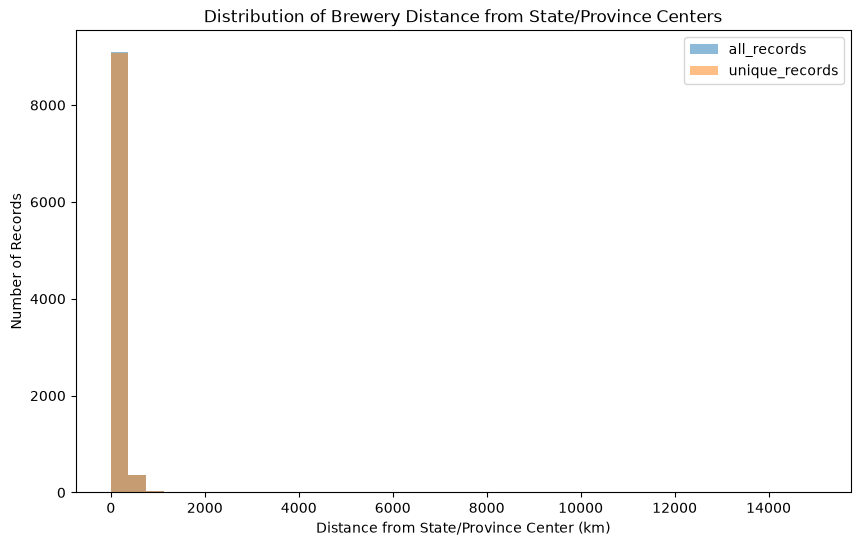

In [42]:
# Distribution of distance from state center.
# The log scale can make both dense near-center observations and long tails easier to see.

# The axes are linear; no log scale is set below.
plt.figure(figsize=(10, 6))

for dataset_name, df in distance_from_center.items():
    plt.hist(
        df["distance_from_state_center_km"].dropna(),
        bins=40,
        alpha=0.5,
        label=dataset_name
    )

plt.xlabel("Distance from State/Province Center (km)")
plt.ylabel("Number of Records")
plt.title("Distribution of Brewery Distance from State/Province Centers")
plt.legend()
plt.show()


The swapped records stretch the x-axis to the 14,996 km of the Labyrinth record, so almost every record falls into the first two bins and the shape near the center is lost. The comment in the cell mentions a log scale, but the plot uses linear axes.

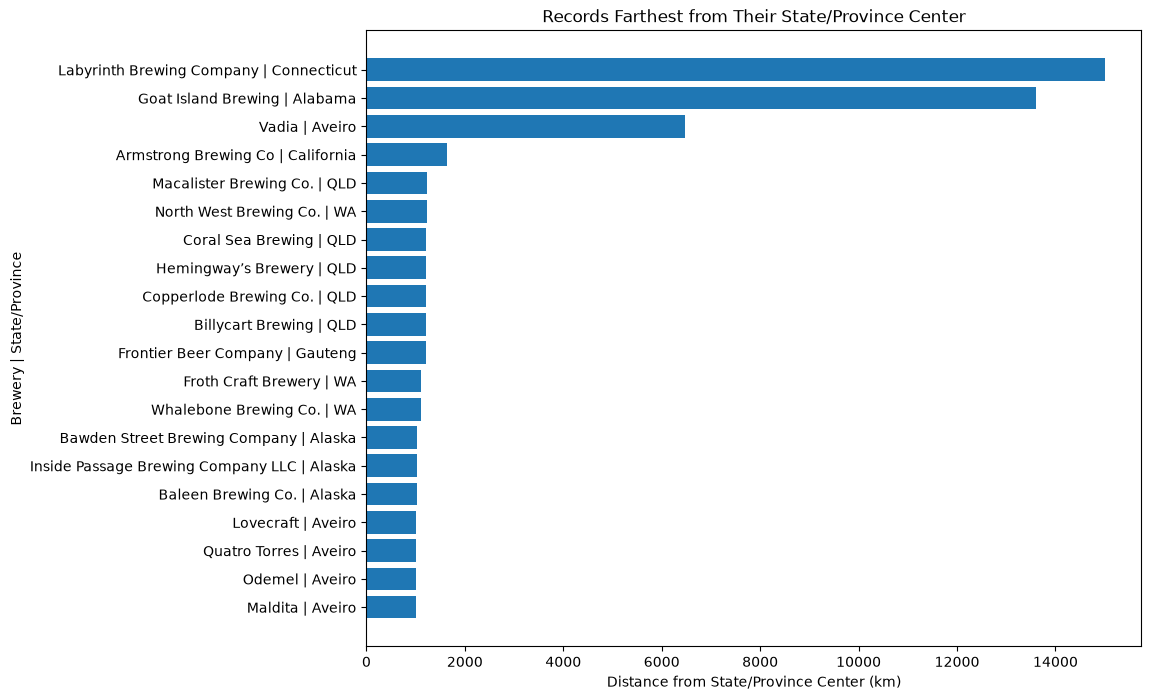

In [43]:
# Show the most distant records from their state/province center.
# These are candidates for investigation, not records to delete automatically.

top_geographic_outliers = (
    geographic_outliers["all_records"]
    .sort_values("distance_from_state_center_km", ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 8))

labels = (
    top_geographic_outliers["name"].astype(str)
    + " | "
    + top_geographic_outliers["state_province"].astype(str)
)

plt.barh(
    labels[::-1],
    top_geographic_outliers["distance_from_state_center_km"].values[::-1]
)

plt.xlabel("Distance from State/Province Center (km)")
plt.ylabel("Brewery | State/Province")
plt.title("Records Farthest from Their State/Province Center")
plt.show()


The top three bars are the swapped records; most of the others are the legitimate remote breweries discussed above. The Geographic Analysis page shows the outliers again with corrected coordinates.

## Geographic Analysis: What This Section Gives Us

At the end of this section, we have a reusable set of geographic outputs:

### Coordinate coverage
- `coordinate_coverage`
- `bounding_box_summary`
- `coordinate_range_checks`

### Geographic centers
- `overall_geographic_center`
- `geographic_centers["all_records"]`
- `geographic_centers["unique_records"]`

### Distance from center
- `distance_from_center["all_records"]`
- `distance_from_center["unique_records"]`

### Spatial dispersion
- `state_spatial_dispersion`
- `state_dispersion_ranked`
- `dispersion_comparison`

### Geographic outliers
- `geographic_outliers`
- `geographic_outlier_summary`

These outputs are intended to become the foundation for the next spatial-analysis stage, where the project can investigate **clusters and geographic concentration** rather than treating distance from a center as the only spatial pattern.

Importantly, geographic outliers are **flagged, not removed**. A distant brewery may represent a real geographic edge or a meaningful regional pattern rather than a data error.


### Later checks

The next cells were added after the summary. They repeat the out-of-range latitude test on the source columns (0 again) and list the columns.

In [44]:
# Same out-of-range test as above, on the source columns of the unique dataset.
invalid_lat_mask = ~analysis_unique_records["latitude"].between(-90, 90)

swap_candidates = analysis_unique_records.loc[
    invalid_lat_mask &
    analysis_unique_records["longitude"].between(-90, 90)
].copy()

len(swap_candidates)

0

In [45]:
analysis_all_records.columns

Index(['id', 'name', 'brewery_type', 'address_1', 'address_2', 'address_3',
       'city', 'state_province', 'postal_code', 'country', 'longitude',
       'latitude', 'phone', 'website_url', 'state', 'street'],
      dtype='str')

In [46]:
invalid_lat_mask = ~analysis_all_records["latitude"].between(-90, 90)

print("Invalid latitude:", invalid_lat_mask.sum())

Invalid latitude: 0


These two cells confirm the duplicate handling. Both ids are Paulaner records in München: the first (website paulaner.de) is in both datasets; the second (paulaner-brauhaus.de) is only in all records. It is the one record the unique dataset removes.

In [47]:
# Paulaner, München (paulaner.de): kept in both datasets.
record_id = "59b8d88c-8628-46d1-bf5e-999cd8e158b4"

print("All records:", analysis_all_records["id"].eq(record_id).any())
print("Unique records:", analysis_unique_records["id"].eq(record_id).any())

All records: True
Unique records: True


In [48]:
# Paulaner, München (paulaner-brauhaus.de): the record the unique dataset drops.
record_id = "0f4b98a6-bc69-4e33-8138-28b75a6ad3c2"

print("All records:", analysis_all_records["id"].eq(record_id).any())
print("Unique records:", analysis_unique_records["id"].eq(record_id).any())

All records: True
Unique records: False
